# Unsupervised Learning in Genomics — Python companion
**Machine Learning for Biomedical Data (MLBD), Week 4**

This notebook follows the R lecture `lectures/week4/genomicsApplications.Rmd`: batch effects and ComBat (`combat` package), Leiden clustering (`igraph` + `leidenalg`), and the single-cell workflow (Scanpy).

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
warnings.filterwarnings("ignore", message="n_jobs value")

LOCAL = "../data/"
REMOTE = "https://raw.githubusercontent.com/wevanjohnson/2026_Fall_MLBD/main/python/data/"
DATA = LOCAL if os.path.exists(LOCAL) else REMOTE

## Batch effects: bladder cancer data
57 bladder samples (normal, cancer, biopsy) processed in 5 batches, from the Bioconductor `bladderbatch` package (the 2,000 most variable genes). PCA is the first diagnostic: color by batch.

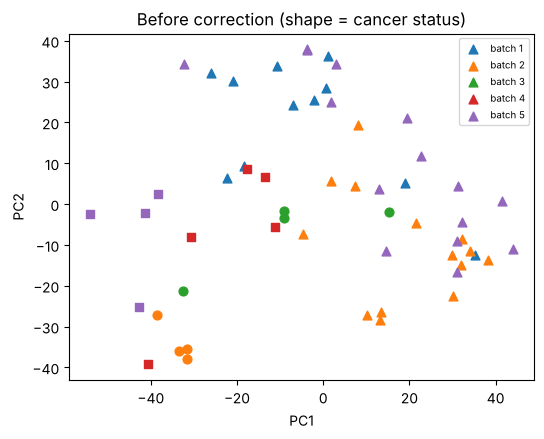

In [2]:
bl = pd.read_csv(DATA + "bladderbatch_top2000.csv")
meta = bl[["sample", "batch", "cancer"]]
expr = bl.drop(columns=["sample", "batch", "cancer"])

def pc_plot(E, title, ax):
    P = PCA(n_components=2).fit_transform(E)
    marks = {"Normal": "o", "Cancer": "^", "Biopsy": "s"}
    for b in sorted(meta.batch.unique()):
        for c, mk in marks.items():
            m = (meta.batch == b) & (meta.cancer == c)
            ax.scatter(P[m, 0], P[m, 1], color=plt.cm.tab10(b - 1), marker=mk, s=40,
                       label=f"batch {b}" if c == "Cancer" else None)
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")

fig, ax = plt.subplots(figsize=(6, 4.5))
pc_plot(expr, "Before correction (shape = cancer status)", ax); ax.legend(fontsize=7)
plt.show()

## Batch correction with ComBat
The `combat` package (`pip install combat`; pyComBat, Behdenna et al. 2023) is a Python port of ComBat (Johnson, Li & Rabinovic, 2007). `mod` protects the biology, like `mod` in `sva::ComBat`. It expects genes in rows and samples in columns. (In R we corrected all 22,283 genes and then plotted the top 2,000; here we correct just the 2,000, so the picture differs a little.)

Scanpy also has `sc.pp.combat`, but with covariates as confounded with batch as these (batch 3 is all normal, batch 4 all biopsy), it gives unstable results here.

Found 5 batches.
Adjusting for 2 covariate(s) or covariate level(s).
Standardizing Data across genes.
Fitting L/S model and finding priors.
Finding parametric adjustments.
Adjusting the Data


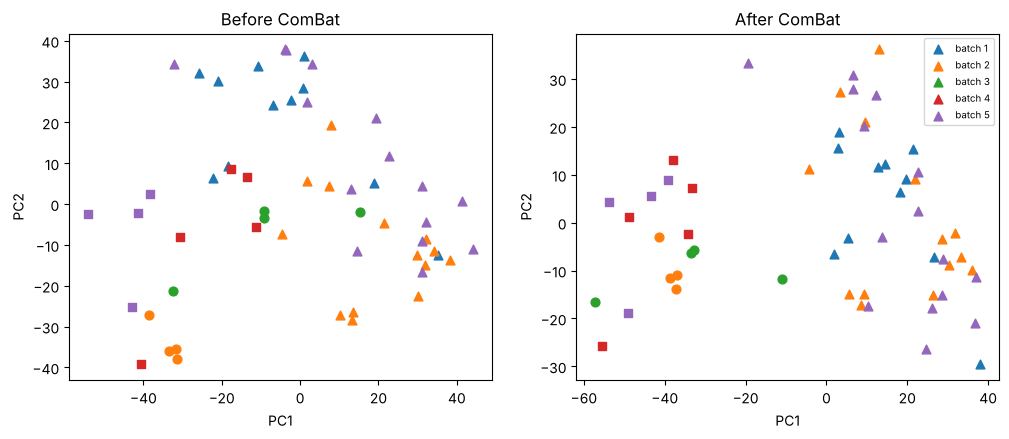

In [3]:
from combat.pycombat import pycombat
expr_cb = pycombat(expr.T, list(meta.batch), mod=list(meta.cancer)).T

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
pc_plot(expr, "Before ComBat", ax[0]); pc_plot(expr_cb, "After ComBat", ax[1])
ax[1].legend(fontsize=7)
plt.show()

## Graph-based clustering: tissue data
The tissue gene expression data from the clustering lecture (189 samples, 500 genes, 7 tissues), centered by gene.

In [4]:
te = pd.read_csv(DATA + "tissue_gene_expression.csv")
tissue = te.pop("tissue")
xt = te - te.mean(axis=0)

## Leiden clustering
Build a 10-nearest-neighbor graph on the top 20 PCs, then run Leiden (modularity) with `igraph` + `leidenalg` (`pip install igraph leidenalg`). Results differ a bit from R's `cluster_leiden`.

In [5]:
import igraph as ig
import leidenalg
from sklearn.neighbors import NearestNeighbors

pcs = PCA(n_components=20).fit_transform(xt)
nn = NearestNeighbors(n_neighbors=11).fit(pcs).kneighbors(pcs, return_distance=False)[:, 1:]
edges = [(i, j) for i in range(len(pcs)) for j in nn[i]]
g = ig.Graph(n=len(pcs), edges=edges).simplify()

part = leidenalg.find_partition(g, leidenalg.ModularityVertexPartition, seed=1)
cl = np.array(part.membership) + 1
print(pd.crosstab(cl, tissue, rownames=["cluster"]))
print("ARI:", round(adjusted_rand_score(tissue, cl), 3))

tissue   cerebellum  colon  endometrium  hippocampus  kidney  liver  placenta
cluster                                                                      
1                 0     34            0            0       0      0         6
2                 5      0            0           31       0      0         0
3                32      0            0            0       0      0         0
4                 0      0            0            0       0     26         0
5                 1      0            0            0      21      0         0
6                 0      0            0            0      18      0         0
7                 0      0           15            0       0      0         0
ARI: 0.799


## Putting it together: single-cell RNA-seq with Scanpy
700 blood cells (PBMCs from Zheng et al., 2017; 765 highly variable genes, log-normalized), with FACS-sorted cell-type labels. Scanpy (`pip install scanpy leidenalg igraph`) runs the standard workflow:

1. scale genes → **PCA**
2. **nearest-neighbor graph** in PC space
3. **Leiden** clustering
4. **UMAP**

The R lecture builds each step by hand; Scanpy wraps each one in a single function.

In [6]:
import anndata as ad
import scanpy as sc
pbmc = pd.read_csv(DATA + "pbmc68k_reduced.csv")
cell_type = pbmc.pop("cell_type")
adata = ad.AnnData(pbmc.to_numpy(),
                   obs=pd.DataFrame({"cell_type": cell_type.values},
                                    index=[f"cell{i}" for i in range(len(pbmc))]))
adata.var_names = pbmc.columns
print(adata)
print(cell_type.value_counts())

AnnData object with n_obs × n_vars = 700 × 765
    obs: 'cell_type'
    layers: None (.X)
cell_type
Dendritic                       240
CD14+ Monocyte                  129
CD19+ B                          95
CD4+/CD25 T Reg                  68
CD8+ Cytotoxic T                 54
CD8+/CD45RA+ Naive Cytotoxic     43
CD56+ NK                         31
CD4+/CD45RO+ Memory              19
CD34+                            13
CD4+/CD45RA+/CD25- Naive T        8
Name: count, dtype: int64


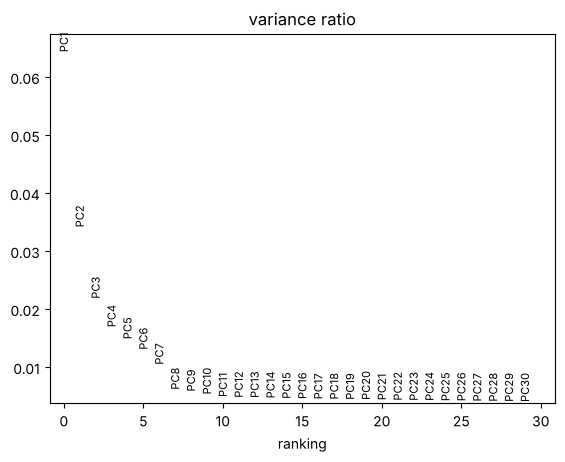

In [7]:
sc.pp.scale(adata)
sc.tl.pca(adata, n_comps=30)
sc.pl.pca_variance_ratio(adata, n_pcs=30)

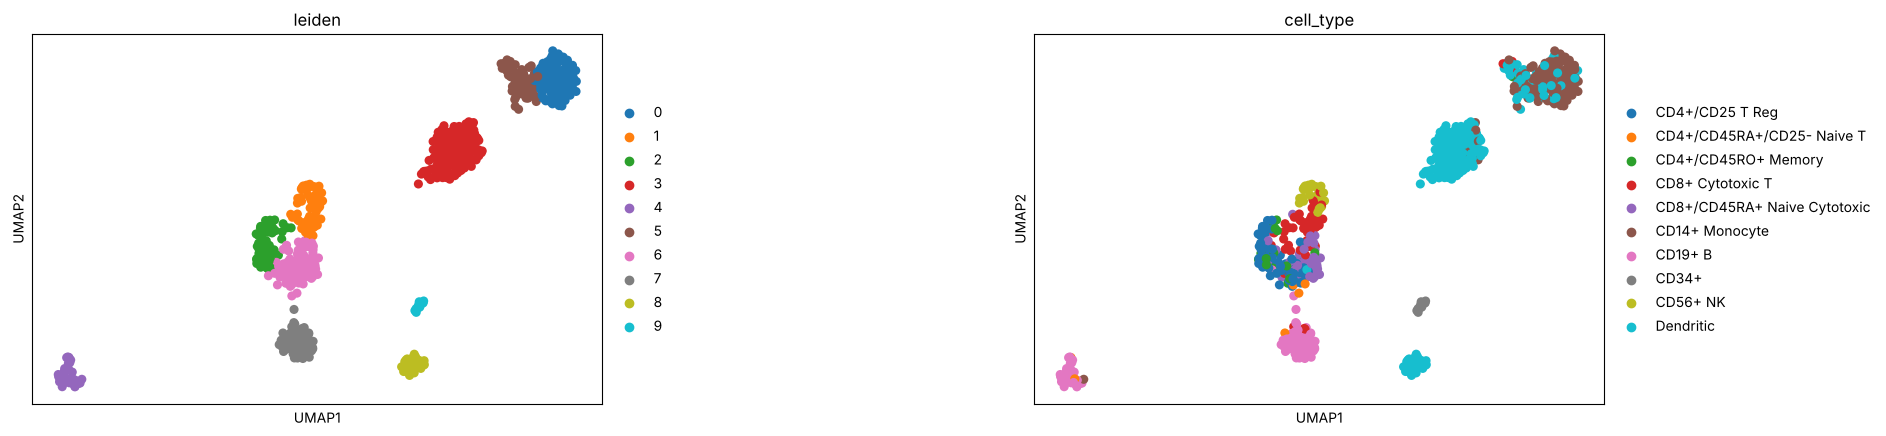

In [8]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=20, random_state=1)
sc.tl.leiden(adata, resolution=1, random_state=1, flavor="igraph", n_iterations=-1, directed=False)
sc.tl.umap(adata, random_state=1)
sc.pl.umap(adata, color=["leiden", "cell_type"], wspace=0.6)

Clusters vs. FACS labels, and the adjusted Rand index:

In [9]:
from sklearn.metrics import adjusted_rand_score
short = {"CD14+ Monocyte": "Mono", "CD19+ B": "B", "CD34+": "CD34",
         "CD4+/CD25 T Reg": "Treg", "CD4+/CD45RA+/CD25- Naive T": "CD4nv",
         "CD4+/CD45RO+ Memory": "CD4mem", "CD56+ NK": "NK", "CD8+ Cytotoxic T": "CD8",
         "CD8+/CD45RA+ Naive Cytotoxic": "CD8nv", "Dendritic": "DC"}
print(pd.crosstab(adata.obs["leiden"], adata.obs["cell_type"].map(short)))
print("ARI:", round(adjusted_rand_score(adata.obs["cell_type"], adata.obs["leiden"]), 3))

cell_type  Treg  CD4nv  CD4mem  CD8  CD8nv  Mono   B  CD34  NK   DC
leiden                                                             
0             0      0       0    0      0    94   0     0   0   23
1             0      0       0   29      4     0   0     0  30    0
2            38      2      11    7      6     0   1     0   0    0
3             0      0       0    0      0     5   0     0   0  152
4             0      2       0    0      0     1  30     0   0    0
5             0      0       1    3      0    29   0     0   0   29
6            30      3       7   12     33     0   1     0   1    1
7             0      1       0    3      0     0  63     0   0    0
8             0      0       0    0      0     0   0     0   0   35
9             0      0       0    0      0     0   0    13   0    0
ARI: 0.496


As in R: monocytes, B cells, and CD34+ progenitors map to their own clusters; T-cell subtypes overlap; NK and cytotoxic T cells share a cluster; and the "Dendritic" bulk labels are noisy. Clusters are hypotheses; marker genes (`sc.tl.rank_genes_groups`) and biology confirm them.